# Lab: Classification with Bank Marketing Data

---

In this lab you will practice building and evaluating **classification models** using a real bank marketing dataset.

The data comes from direct marketing campaigns conducted by a Portuguese banking institution. The campaigns were based on phone calls, and the classification goal is to predict whether a client will subscribe to a term deposit.

We will use the official `bank.csv` sample from the **UCI Bank Marketing dataset**. It is a 10% random sample of the larger dataset and is useful here because we will train several KNN models while choosing a value of `k`.

**Source:** UCI Machine Learning Repository — Bank Marketing  
https://archive.ics.uci.edu/dataset/222/bank+marketing

**Target:** `y`
- `yes` = client subscribed to a term deposit
- `no` = client did not subscribe

### Data Dictionary

| Variable | Description |
|---|---|
| `age` | Client age |
| `job` | Type of job |
| `marital` | Marital status |
| `education` | Education level |
| `default` | Whether the client has credit in default |
| `balance` | Average yearly account balance, in euros |
| `housing` | Whether the client has a housing loan |
| `loan` | Whether the client has a personal loan |
| `contact` | Contact communication type |
| `day` | Day of the month of the last contact |
| `month` | Month of the last contact |
| `duration` | Duration of the last contact, in seconds |
| `campaign` | Number of contacts performed during the current campaign |
| `pdays` | Days since the client was last contacted in a previous campaign (`-1` means not previously contacted) |
| `previous` | Number of contacts performed before the current campaign |
| `poutcome` | Outcome of the previous marketing campaign |
| `y` | Whether the client subscribed to the term deposit (`yes` / `no`) |

#### Understanding the Bank Marketing Features

Think of each row as describing a client at the time of a contact in the **current marketing campaign**.

##### Timeline

```text
CLIENT INFORMATION — already known
│
├── age        → client's age
├── job        → occupation
├── marital    → marital status
├── education  → education level
├── default    → has credit in default?
├── balance    → account balance
├── housing    → has housing loan?
└── loan       → has personal loan?
│
│
▼
PREVIOUS MARKETING CAMPAIGN(S)
│
├── previous   → number of contacts made BEFORE the current campaign
├── poutcome   → outcome of the previous campaign
│
└── Last contact from a previous campaign
        │
        │
        │  pdays
        │  = number of days since this previous contact
        │
        ▼
CURRENT MARKETING CAMPAIGN
│
├── Current contact is about to take place
│
├── month      → month of the current contact
├── day        → day of the current contact
├── contact    → contact method (e.g. cellular / telephone)
├── campaign   → contact number during this campaign (includes the current contact)
│
│                 Example:
│                 Call 1 → Call 2 → Call 3
│                                      ↑
│                                campaign = 3
│
▼
CURRENT PHONE CALL
│
├── duration   → how long this current contact/call lasted
│
▼
CAMPAIGN OUTCOME
│
└── y          → Did the client subscribe to a term deposit?
    
```

### 1. Download and read in the Bank Marketing data.

Download the UCI Bank Marketing archive and extract `bank.csv`.

Then:

1. Read the CSV into a pandas dataframe.
2. Remember that this file uses `;` as the separator.
3. Display the first five rows.

In [40]:
#1, 2 & 3.
import pandas as pd

bank_df = pd.read_csv('bank.csv', sep=';')

bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


### 2. Conduct an initial exploration of the dataset.

Complete the following:

1. Check the shape of the dataset.
2. Inspect the data types and missing values.
3. Display summary statistics.
4. Check the distribution of the target variable `y`, including percentages.
5. Is this a balanced or imbalanced classification problem? Explain briefly.

In [41]:
#1.
bank_df.shape

(4521, 17)

In [42]:
#2.
bank_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


In [43]:
#2.
bank_df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [44]:
#3. 
bank_df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [45]:
#4.
print("Counts:")
print(bank_df['y'].value_counts())

print("\nPercentages:")
print(bank_df['y'].value_counts(normalize=True) * 100)

Counts:
y
no     4000
yes     521
Name: count, dtype: int64

Percentages:
y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64


In [46]:
# Q5)
# This is an imbalanced classification problem because approximately 88.48% of clients 
# did not subscribe to a term deposit (no), while only 11.52% subscribed (yes). 
# The no class is much more common than the yes class. 
# Therefore, accuracy alone may not fully reflect the model's performance, and precision, 
# recall, and F1-score can also help evaluate how well the model identifies clients who subscribe.

### 3. Define the business problem and choose an evaluation metric.

Assume the bank wants to use the model to decide **which clients should be prioritized for future marketing calls**.

Answer the following:

1. What does a **False Positive** mean in this business problem? What is the cost of this error?
2. What does a **False Negative** mean? What is the cost of this error?
3. Assume the bank considers both errors important, which metric would you choose?
4. Why might **Accuracy** be misleading for this dataset?

#### Answers

In [47]:
#1.
# A False Positive (FP) occurs when the model predicts that a client will subscribe to a term deposit 
# (yes), but the client actually does not subscribe (no). 
# The bank may waste time and resources contacting clients who are unlikely to subscribe, 
# increasing marketing costs.

In [48]:
#2.
#A False Negative (FN) occurs when the model predicts that a client will not subscribe (no),
#  but the client actually would subscribe (yes). 
# The bank may miss an opportunity to contact a potentially interested client, 
# resulting in a lost business opportunity and potential revenue.

In [49]:
#3.
#I would choose the F1-score because it combines Precision and Recall into one metric. 
# Precision measures how many clients predicted as likely to subscribe actually subscribe, 
# while Recall measures how many actual subscribers the model correctly identifies. 
# Since the bank considers both false positives and false negatives important, the F1-score provides a 
# balance between these two concerns.

In [50]:
#4.
#Accuracy may be misleading because the target variable is imbalanced: 
# approximately 88.48% of clients did not subscribe, while only 11.52% did. 
# A model that predicts no for every client could achieve approximately 88.48% accuracy 
# while failing to identify any clients who would subscribe. 
# Therefore, accuracy alone does not show how effectively the model identifies potential subscribers. 
# Precision, Recall, and F1-score provide additional information about its performance.

### 4. Check for information that would lead to data leakage.

The goal is to prioritize clients **before making the marketing call**.

Review the data dictionary and identify any variable that would only become known after the call has already taken place.

1. Which variable should be removed?
2. Why would keeping it create a data leakage / unrealistic prediction problem?
3. Drop the variable from the dataframe.

#### Answers:

In [51]:
#1.
# The variable to remove is duration, 
# which represents the duration of the last contact with the client.

In [52]:
#2.
#The goal is to predict which clients should be prioritized before making the marketing call. 
# The duration variable is only known after the call has taken place, 
# so it would not be available when the bank needs to make its decision. 
# Keeping it could give the model information that would not be available in real-world predictions, 
# resulting in unrealistic performance estimates.

In [53]:
#3.
bank_df.drop(columns=['duration'], inplace=True)

### 5. Encode binary categorical variables

Complete the following:

1. Identify the predictor columns containing only `yes` and `no`.
2. Map these columns to `0` and `1`.

> This mapping can be done before the train/test split because it follows a fixed rule and does not learn any information from the dataset.

In [54]:
#1.
binary_cols = [
    col for col in bank_df.columns
    if set(bank_df[col].dropna().unique()) == {'yes', 'no'}
    and col != 'y'
]

binary_cols

['default', 'housing', 'loan']

In [55]:
#2.
for col in binary_cols:
    bank_df[col] = bank_df[col].map({
        'yes': 1,
        'no': 0
    })

bank_df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,0,1787,0,0,cellular,19,oct,1,-1,0,unknown,no
1,33,services,married,secondary,0,4789,1,1,cellular,11,may,1,339,4,failure,no
2,35,management,single,tertiary,0,1350,1,0,cellular,16,apr,1,330,1,failure,no
3,30,management,married,tertiary,0,1476,1,1,unknown,3,jun,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,0,0,1,0,unknown,5,may,1,-1,0,unknown,no


### 6. Prepare the target and split the data.

Complete the following:

1. Create `X` and `y`.
2. Split the data into training and testing sets.

In [56]:
#1.
X = bank_df.drop(columns=['y'])
y = bank_df['y']

In [57]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4521, 15)
y shape: (4521,)


In [58]:
#2.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [59]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3616, 15)
X_test: (905, 15)
y_train: (3616,)
y_test: (905,)


### 7. Preprocess the training and testing sets

The dataset contains both numerical and categorical variables. Also, there is imbalance in your dataset

#### Part A: Scaling the numerical features

For now, let's transform the numerical ones.

Complete the following:

1. Create a list of numerical columns.
2. Create a `StandardScaler` for the numerical columns.
    - Fit the scaler on the numerical columns of `X_train` only.
    - Use the fitted scaler to transform both `X_train` and `X_test`.
3. Store the scaled numerical values back into their original columns in `X_train` and `X_test`
    - No need to use `.set_output()`
4. Why do we need to scale our data if our model of choice is KNN?


In [60]:
#1.
numerical_cols = X.select_dtypes(include='number').columns.tolist()
numerical_cols

['age',
 'default',
 'balance',
 'housing',
 'loan',
 'day',
 'campaign',
 'pdays',
 'previous']

In [61]:
#2.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().set_output(transform='pandas')

scaler.fit(X_train[numerical_cols])

StandardScaler()

In [62]:
#3.
X_train[numerical_cols] = scaler.transform(X_train[numerical_cols])

X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

In [63]:
X_train[numerical_cols].head()

,age,default,balance,housing,loan,day,campaign,pdays,previous
2236,-0.864347,7.169784,-0.505865,0.871556,-0.427620,-0.492444,0.065082,-0.411541,-0.329453
858,-0.673204,-0.139474,-0.448232,0.871556,2.338524,-0.248716,-0.570967,0.447116,11.136987
3531,0.282513,-0.139474,-0.499461,-1.147373,-0.427620,0.726196,-0.252942,-0.411541,-0.329453
2737,-0.673204,-0.139474,2.456534,0.871556,2.338524,0.360604,-0.570967,-0.411541,-0.329453
1257,0.951514,-0.139474,1.297118,-1.147373,2.338524,-0.004988,1.337181,-0.411541,-0.329453


In [64]:
#4.
#KNN calculates distances between observations. 
# Without scaling, features with larger numerical ranges, such as balance, 
# could dominate the distance calculation. 
# Standardization makes the numerical features more comparable, 
# helping KNN determine the nearest neighbors more fairly.

#### Part B: Balancing the training data

Regular `SMOTE` creates synthetic observations by interpolating between neighboring observations. This works well for numerical features, but it is not suitable for categorical features.

Instead, we will use **SMOTENC**, a version of SMOTE designed for datasets containing both numerical and categorical features.

We will apply SMOTENC **before One-Hot Encoding**.

**Why?**

- After One-Hot Encoding, one categorical feature such as `job` becomes several binary columns:

    - `job_admin`, `job_student`, `job_retired`, ...
    
- If we used regular SMOTE after One-Hot Encoding, interpolation could create invalid values such as:

    - `job_admin = 0.4`, `job_student = 0.6`

- which do not represent a real category.

- So applying the resampler at this stage allows us to assign the synthetic sample the most common category among the selected minority-class neighbors.

Complete the following:

1. Identify the categorical columns in the training set.
2. Create a `SMOTENC` resampler:
   - specify which columns are categorical
   - use the default value for `k_neighbors`
   - let the minority class size be **50% of the majority class**
3. Apply the `SMOTENC` **only to the training set**.
4. Compare the training target distribution before and after `SMOTENC`.
5. Why should `SMOTENC` only be applied to the training data?
6. What is the effect of `k_neighbors` when `SMOTENC` creates synthetic observations?

In [65]:
#1.
categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

categorical_cols

C:\Users\DELL\AppData\Local\Temp\ipykernel_37900\3640052862.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


['job', 'marital', 'education', 'contact', 'month', 'poutcome']

In [66]:
#2.
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=categorical_cols,
    sampling_strategy=0.5,
    random_state=42
)

In [67]:
#3. 
X_train_resampled, y_train_resampled = smotenc.fit_resample( X_train,y_train)

In [68]:
#4. 
print("Before SMOTENC:")
print(y_train.value_counts())

print("\nAfter SMOTENC:")
print(y_train_resampled.value_counts())

Before SMOTENC:
y
no     3199
yes     417
Name: count, dtype: int64

After SMOTENC:
y
no     3199
yes    1599
Name: count, dtype: int64


In [69]:
print("Before SMOTENC (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nAfter SMOTENC (%):")
print(y_train_resampled.value_counts(normalize=True) * 100)

Before SMOTENC (%):
y
no     88.46792
yes    11.53208
Name: proportion, dtype: float64

After SMOTENC (%):
y
no     66.673614
yes    33.326386
Name: proportion, dtype: float64


In [70]:
#5.
# SMOTENC should only be applied to the training data to prevent data leakage and preserve 
# the original distribution of the testing data. The testing set should represent unseen, 
# real-world observations so that we can evaluate the model fairly. 
# Applying SMOTENC to the testing set would artificially change its class distribution and could lead 
# to an unreliable evaluation.

In [71]:
#6.
# The k_neighbors parameter determines how many nearest minority-class neighbors are considered 
# when generating synthetic observations. The default value is 5, 
# meaning that SMOTENC uses five nearest neighbors to help generate new samples. 
# Changing this value affects the neighborhood used to create synthetic observations and may 
# influence the characteristics of the resampled training data.

#### Part C: Encoding the categorical features

After resampling our trainig set, we can start encoding.

Complete the following:

1. Create a `OneHotEncoder` for the categorical columns.
    - Use `.set_output()` for this part
    - Fit the encoder on the categorical columns of your **balanced training** set.
    - Use the fitted encoder to transform both the **balanced training** and **unbalanced testing** set.

2. Concatenate the numerical and encoded categorical features to create the final processed training and testing datasets.
    - For the training set, extract the numerical features from the **balanced transformed** training data and combine them with the **encoded categorical** training features.
    - For the test set, extract the numerical features from the **unbalanced transformed** test data and combine them with the **encoded categorical** test features.


In [72]:
#1.
# -------------------------
# Encode categorical features
# -------------------------

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
).set_output(transform='pandas')

X_train_cat = encoder.fit_transform(
    X_train_resampled[categorical_cols]
)

X_test_cat = encoder.transform(
    X_test[categorical_cols]
)


In [73]:
#2.
# -------------------------
# Combine numerical + encoded categorical features
# -------------------------

X_train_num = X_train_resampled.drop(columns=categorical_cols)

X_test_num = X_test.drop(columns=categorical_cols)

X_train_final = pd.concat(
    [X_train_num, X_train_cat],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num, X_test_cat],
    axis=1
)

In [74]:
print("Training set shape:", X_train_final.shape)
print("Testing set shape:", X_test_final.shape)

Training set shape: (4798, 47)
Testing set shape: (905, 47)


In [75]:
X_train_final.head()

,age,default,balance,housing,loan,day,campaign,pdays,previous,job_admin.,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,-0.864347,7.169784,-0.505865,0.871556,-0.427620,-0.492444,0.065082,-0.411541,-0.329453,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.673204,-0.139474,-0.448232,0.871556,2.338524,-0.248716,-0.570967,0.447116,11.136987,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,0.282513,-0.139474,-0.499461,-1.147373,-0.427620,0.726196,-0.252942,-0.411541,-0.329453,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.673204,-0.139474,2.456534,0.871556,2.338524,0.360604,-0.570967,-0.411541,-0.329453,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.951514,-0.139474,1.297118,-1.147373,2.338524,-0.004988,1.337181,-0.411541,-0.329453,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [76]:
X_test_final.head()

,age,default,balance,housing,loan,day,campaign,pdays,previous,job_admin.,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
2032,1.716087,-0.139474,0.114933,-1.147373,-0.42762,1.091788,0.383107,3.172855,0.877541,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
943,-0.099774,-0.139474,-0.460684,-1.147373,-0.42762,0.482468,6.107549,-0.411541,-0.329453,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
408,0.282513,-0.139474,-0.343639,0.871556,-0.42762,-0.979900,0.065082,2.623713,0.274044,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3034,-1.151062,-0.139474,-0.535749,-1.147373,-0.42762,-1.467356,-0.570967,-0.411541,-0.329453,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3447,1.142658,-0.139474,-0.447521,-1.147373,-0.42762,1.701108,-0.570967,-0.411541,-0.329453,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


---

## Logistic Regression

### 8. Train a Logistic Regression classification model.

Now:

1. Create a `LogisticRegression` model.
2. Fit the model 

In [77]:
#1.
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(random_state=42)

In [78]:
#2.
logreg.fit(X_train_final, y_train_resampled)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

### 9. Evaluate the Logistic Regression model.

Generate predictions and predicted probabilities for the test set.

Calculate:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also:

1. Display the confusion matrix.
2. Plot the ROC curve. 
    - How would you interpret the graph?
3. Based on the business objective from Question 3, which metric should receive the most attention?

In [79]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)
import matplotlib.pyplot as plt

def evaluation(X_test, y_test, preds, model, y_prob):

    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, cmap='Blues'
    )
    plt.show()

    acc = accuracy_score(y_test, preds)
    b_acc = balanced_accuracy_score(y_test, preds)
    recall = recall_score(y_test, preds, pos_label='yes')
    prec = precision_score(y_test, preds, pos_label='yes')
    f1 = f1_score(y_test, preds, pos_label='yes')
    roc_auc = roc_auc_score(
        (y_test == 'yes').astype(int), y_prob
    )

    print(f'Accuracy: {acc:.4f}')
    print(f'Balanced Accuracy: {b_acc:.4f}')
    print(f'Recall: {recall:.4f}')
    print(f'Precision: {prec:.4f}')
    print(f'F1 Score: {f1:.4f}')
    print(f'ROC AUC: {roc_auc:.4f}')

    return {
        'accuracy': acc,
        'balanced_accuracy': b_acc,
        'recall': recall,
        'precision': prec,
        'f1_score': f1,
        'roc_auc': roc_auc
    }

In [80]:
y_pred = logreg.predict(X_test_final)

yes_index = list(logreg.classes_).index('yes')
y_prob = logreg.predict_proba(X_test_final)[:, yes_index]

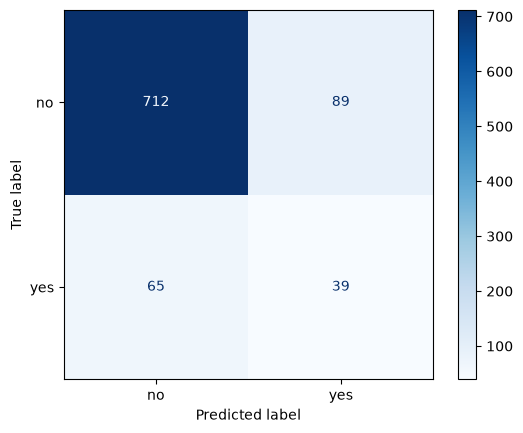

Accuracy: 0.8298
Balanced Accuracy: 0.6319
Recall: 0.3750
Precision: 0.3047
F1 Score: 0.3362
ROC AUC: 0.7054


In [81]:
#1.
logreg_results = evaluation(
    X_test_final,
    y_test,
    y_pred,
    logreg,
    y_prob
)

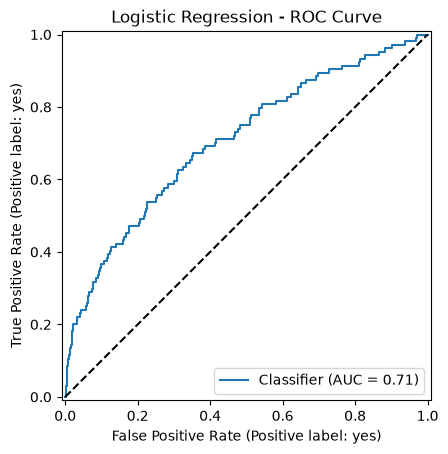

In [82]:
#2.
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob, pos_label='yes')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Logistic Regression - ROC Curve')
plt.show()

In [83]:
#3.
# The Logistic Regression model achieved an accuracy of 82.98% and a ROC AUC of 0.7054, 
# indicating moderate ability to distinguish between subscribers and non-subscribers. 
# However, its recall of 37.50% shows that it misses many potential subscribers. 
# Since the bank wants to prioritize customers for marketing calls, recall is an important metric, 
# although precision must also be considered to avoid wasting marketing resources.

### 10. Interpret the Logistic Regression coefficients.

1. Extract the fitted Logistic Regression coefficients and convert them into **odds ratios** using:

```python
np.exp(coefficient)
```

2. Create a dataframe containing:

- feature name
- coefficient
- odds ratio

Then:

3. Sort the table by coefficient.
4. Identify features associated with higher odds of subscription.
5. Identify features associated with lower odds of subscription.
6. Interpret at least **two odds ratios** in words.

**Important:**
- Numerical variables were standardized, so a one-unit change for them means approximately a **one standard deviation increase**.
- One-hot encoded categorical variables are interpreted relative to the category that was dropped as the reference group.

In [84]:
#1, 2 & 3.
import numpy as np
import pandas as pd

feature_names = X_train_final.columns

coefficients = logreg.coef_[0]

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients,
    'odds_ratio': np.exp(coefficients)
})

coef_df = coef_df.sort_values(
    by='coefficient',
    ascending=False
).reset_index(drop=True)

coef_df

,feature,coefficient,odds_ratio
0,poutcome_success,1.473297,4.363600
1,month_oct,1.254615,3.506487
2,job_retired,1.071006,2.918313
3,education_secondary,0.696699,2.007116
4,contact_cellular,0.667044,1.948469
5,job_management,0.609277,1.839102
6,month_jun,0.509741,1.664860
7,job_student,0.277482,1.319803
8,education_tertiary,0.277063,1.319249
9,job_blue-collar,0.248812,1.282501


In [85]:
#4 & 5.
higher_odds = coef_df[coef_df['coefficient'] > 0]

lower_odds = coef_df[coef_df['coefficient'] < 0]

print("Features associated with HIGHER odds:")
display(higher_odds)

print("Features associated with LOWER odds:")
display(lower_odds)

Features associated with HIGHER odds:


,feature,coefficient,odds_ratio
0,poutcome_success,1.473297,4.363600
1,month_oct,1.254615,3.506487
2,job_retired,1.071006,2.918313
3,education_secondary,0.696699,2.007116
4,contact_cellular,0.667044,1.948469
5,job_management,0.609277,1.839102
6,month_jun,0.509741,1.664860
7,job_student,0.277482,1.319803
8,education_tertiary,0.277063,1.319249
9,job_blue-collar,0.248812,1.282501


Features associated with LOWER odds:


,feature,coefficient,odds_ratio
17,default,-0.003027,0.996978
18,month_feb,-0.010267,0.989785
19,balance,-0.056416,0.945146
20,month_may,-0.064882,0.937178
21,marital_single,-0.075845,0.926959
22,month_sep,-0.076724,0.926145
23,job_technician,-0.095872,0.908581
24,housing,-0.170858,0.842941
25,month_apr,-0.215202,0.806379
26,marital_married,-0.233595,0.791682


In [86]:
#6.
# Example 1: poutcome_success
# The odds ratio is 4.3636.
# (4.3636-1) x 100% = 336.36%
# Holding other features constant, customers whose previous campaign outcome was successful have 
# estimated odds of subscribing approximately 336.36% higher than customers in the reference 
# category for poutcome.

# Example 2: month_jan
# The odds ratio is 0.3455.
# (1-0.3455) 100% = 65.45%
# Holding other features constant, customers contacted in January have estimated odds of subscribing 
# approximately 65.45% lower than customers contacted in the reference month for month.

---

## K-Nearest Neighbors

### 11. Train a KNN classification model.

#### Part A: Train KNN models for different values of `k`

Run a KNN model for several odd values of `k` and capture the resulting metric you previously selected in a list.

Every loop iteration should:

1. Train a model with a specific `k` value.
2. Calculate the training score.
3. Calculate the testing score.
4. Create a dictionary storing `k`, the training score and the testing score.
5. Append the dictionary to a `scores` list.

You can test values such as:

```python
range(3, 22, 2)
```

In [87]:
#1, 2, 3, 4 & 5.
from sklearn.neighbors import KNeighborsClassifier

scores = []

for k in range(3, 22, 2):

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_final, y_train_resampled)

    train_score = knn.score(X_train_final, y_train_resampled)

    test_score = knn.score(X_test_final, y_test)

    y_pred_knn = knn.predict(X_test_final)
    recall = recall_score(y_test, y_pred_knn, pos_label='yes')

    scores.append({
        'k': k,
        'train_score': train_score,
        'test_score': test_score,
        'recall': recall
    })

scores

[{'k': 3,
  'train_score': 0.9199666527719883,
  'test_score': 0.7767955801104972,
  'recall': 0.2980769230769231},
 {'k': 5,
  'train_score': 0.8943309712380159,
  'test_score': 0.7701657458563536,
  'recall': 0.36538461538461536},
 {'k': 7,
  'train_score': 0.8766152563568154,
  'test_score': 0.7646408839779005,
  'recall': 0.40384615384615385},
 {'k': 9,
  'train_score': 0.8599416423509796,
  'test_score': 0.7624309392265194,
  'recall': 0.4230769230769231},
 {'k': 11,
  'train_score': 0.8497290537724052,
  'test_score': 0.7558011049723757,
  'recall': 0.4230769230769231},
 {'k': 13,
  'train_score': 0.8434764485202167,
  'test_score': 0.7613259668508288,
  'recall': 0.4230769230769231},
 {'k': 15,
  'train_score': 0.8370154230929554,
  'test_score': 0.7513812154696132,
  'recall': 0.4230769230769231},
 {'k': 17,
  'train_score': 0.834722801167153,
  'test_score': 0.7602209944751381,
  'recall': 0.41346153846153844},
 {'k': 19,
  'train_score': 0.8297207169654023,
  'test_score': 0.

#### Part B: Plot the results for the different values of `k`

1. In the same plot, graph the training and testing scores against `k`.
2. Choose a value of `k` that gives strong performance without a large gap between training and test values.

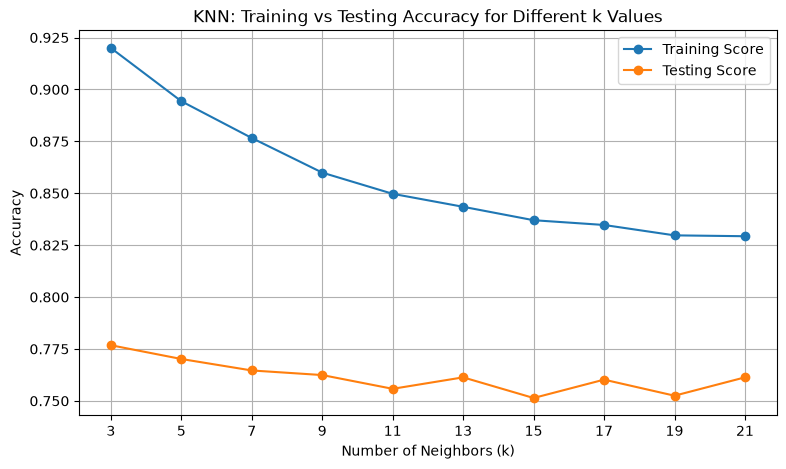

In [88]:
#1.
scores_df = pd.DataFrame(scores)

plt.figure(figsize=(9, 5))

plt.plot(
    scores_df['k'],
    scores_df['train_score'],
    marker='o',
    label='Training Score'
)

plt.plot(
    scores_df['k'],
    scores_df['test_score'],
    marker='o',
    label='Testing Score'
)

plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.title('KNN: Training vs Testing Accuracy for Different k Values')
plt.xticks(scores_df['k'])
plt.legend()
plt.grid(True)
plt.show()

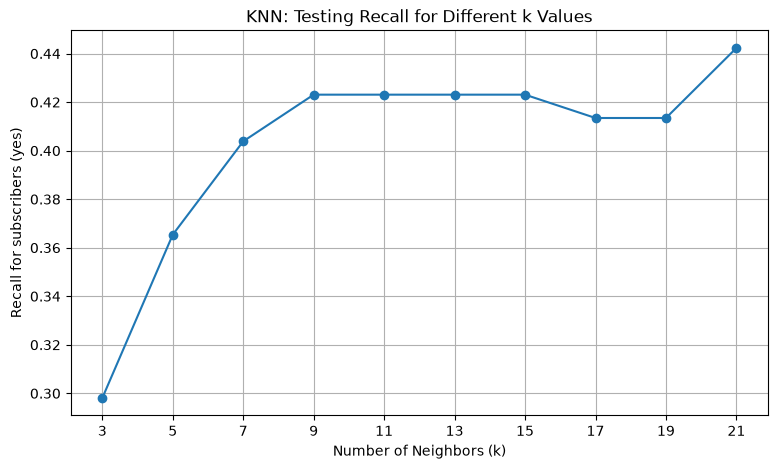

In [89]:
plt.figure(figsize=(9, 5))
plt.plot(scores_df['k'], scores_df['recall'], marker='o')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Recall for subscribers (yes)')
plt.title('KNN: Testing Recall for Different k Values')
plt.xticks(scores_df['k'])
plt.grid(True)
plt.show()

In [90]:
#2.
#Based on the training and testing score plots, I would choose k=21. 
# Although its testing accuracy is slightly lower than the maximum testing accuracy, 
# it has a smaller gap between training and testing scores, suggesting better generalization.

#Furthermore, k=21 achieves the highest testing recall among the tested values, approximately 0.44. 
# This means the model identifies about 44% of customers who actually subscribe to the term deposit. 
# Since the bank wants to identify potential subscribers for marketing calls, 
# recall is particularly important.

#Therefore, k=21 is a reasonable choice because it provides a better balance between 
# generalization and identifying potential subscribers, even though its overall testing accuracy 
# is not the highest.

#### Part C:  Build the final KNN model.

Using the `k` value selected in Question 11:

1. Train your final KNN model

In [91]:
final_knn = KNeighborsClassifier(n_neighbors=21)
final_knn.fit(X_train_final, y_train_resampled)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",21
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['no','yes']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### 12. Evaluate the final KNN model.

Using the untouched test set, calculate the same metrics used for Logistic Regression:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also display:

1. The confusion matrix.
2. The ROC curve.

In [92]:
preds_knn = final_knn.predict(X_test_final)

yes_index = list(final_knn.classes_).index('yes')
y_prob_knn = final_knn.predict_proba(X_test_final)[:, yes_index]

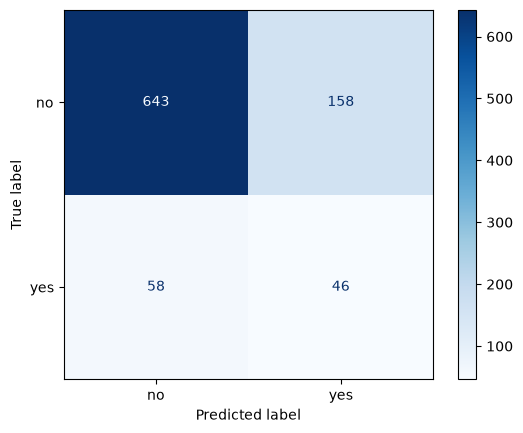

Accuracy: 0.7613
Balanced Accuracy: 0.6225
Recall: 0.4423
Precision: 0.2255
F1 Score: 0.2987
ROC AUC: 0.6738


In [93]:
#1.
knn_results = evaluation(
    X_test_final,
    y_test,
    preds_knn,
    final_knn,
    y_prob_knn
)

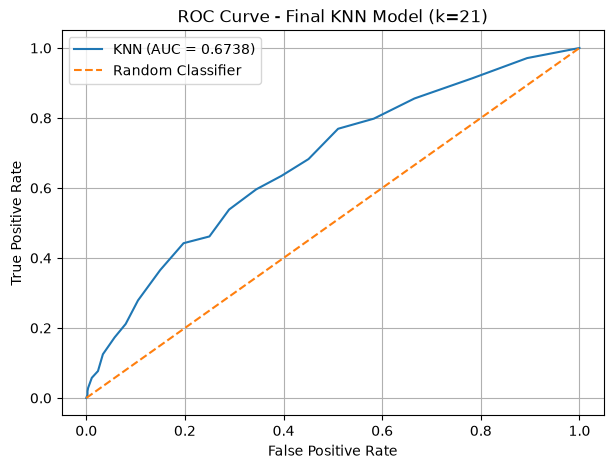

In [94]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    (y_test == 'yes').astype(int),
    y_prob_knn
)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"KNN (AUC = {knn_results['roc_auc']:.4f})")
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Final KNN Model (k=21)')
plt.legend()
plt.grid(True)
plt.show()

### 14. Compare the models and make a business recommendation.

Create a table comparing Logistic Regression and KNN using the test-set metrics.

Then answer:

1. Which model performs better for the business objective defined earlier?
2. What trade-off do you see between Precision and Recall?
3. Would you recommend Logistic Regression or KNN to the marketing team? Why?
4. Besides predictive performance, what advantage does Logistic Regression have when the business wants to understand **why** a client is more or less likely to subscribe?

Your recommendation should be based on the business objective — not simply on whichever model has the highest Accuracy.

In [95]:
comparison_df = pd.DataFrame({
    'Logistic Regression': logreg_results,
    'KNN': knn_results
})

comparison_df = comparison_df.loc[
    ['accuracy', 'balanced_accuracy', 'precision',
     'recall', 'f1_score', 'roc_auc']
]

comparison_df.index = [
    'Accuracy',
    'Balanced Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC AUC'
]

display(comparison_df.round(4))

,Logistic Regression,KNN
Accuracy,0.8298,0.7613
Balanced Accuracy,0.6319,0.6225
Precision,0.3047,0.2255
Recall,0.3750,0.4423
F1 Score,0.3362,0.2987
ROC AUC,0.7054,0.6738


In [96]:
#1.
# Logistic Regression performs better overall, achieving higher Balanced Accuracy, 
# Precision, F1 Score, and ROC AUC. It also has higher Accuracy.
# However, KNN has higher Recall (0.4423 compared with 0.3750). 
# This means KNN identifies a larger proportion of actual subscribers, 
# making it potentially useful if the bank's main objective is to avoid missing potential customers.

In [97]:
#2.
# Logistic Regression has higher Precision (0.3047), 
# meaning that among customers it predicts will subscribe, 
# a larger proportion actually subscribe.

# KNN has higher Recall (0.4423), meaning it identifies more of the customers who actually subscribe. 
# However, its lower Precision (0.2255) means more of its predicted subscribers do not actually subscribe.

# Therefore, the trade-off is between contacting more potential subscribers and reducing marketing 
# effort spent on customers who do not subscribe.

In [98]:
#3. 
# I would recommend Logistic Regression as the initial model for the marketing team. 
# It achieves higher Accuracy, Balanced Accuracy, Precision, F1 Score, and ROC AUC, 
# indicating stronger overall performance on the test set. Its higher Precision could also help 
# the bank use its marketing resources more efficiently.

# However, if the bank prioritizes identifying as many potential subscribers as possible, 
# it should consider KNN because of its higher Recall. The final choice should depend on the 
# relative cost of missed subscribers and unnecessary marketing calls.

In [99]:
#4.
# Logistic Regression is more interpretable because its coefficients and odds ratios help explain 
# how individual features are associated with subscription likelihood, 
# while holding other features constant.

# For example, the earlier model showed an odds ratio of approximately 4.36 for poutcome_success. 
# This indicates that customers in this category had estimated subscription odds 
# about 4.36 times those of the reference category, with the other included features held constant.

# This allows the marketing team to understand which customer characteristics are associated 
# with subscribing and use those insights to inform campaign decisions. 
# These relationships are associations, not proof of causation.

In [100]:
# Final conclusion: 
# Logistic Regression is the stronger overall model based on your test-set metrics and offers 
# the additional benefit of interpretability. 
# KNN may be preferable if maximizing Recall is the bank's overriding priority. 
# The best business decision depends on the costs of missed subscribers versus unnecessary calls, 
# not Accuracy alone.